# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024160080       # <-- your full roll number
NAME = "Abhinav"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160080   Name: Abhinav   Fingerprint: 757169AA   Tickets: 12

Ticket_ID                                                                                         Ticket_Text
      T01                                   The printer was working yesterday. The same problem occurs again.
      T02                                   I can't open the printer after the latest update. This is urgent.
      T03 I keep getting logged out of the laptop before the assignment deadline. I have tried several times!
      T04                                                      The projector stopped responding. Please help.
      T05                                          E-mail failed to open during the lab. It worked yesterday.
      T06                                                               I tried again... still no response!!!
      T07                                                                Email me at helpdesk@university.edu.
      T08                                

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Q1: Apply the official preprocessing pipeline to every ticket.
rows = []
total_sentences = total_tokens = total_punct = total_stops = total_final = 0
all_tokens, all_final = [], []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    unique_tokens = list(dict.fromkeys(result["tokens"]))
    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": result["sentences"],
        "Tokens": result["tokens"],
        "Punctuation": result["punct"],
        "Stopwords": result["stops"],
        "Unique tokens": unique_tokens,
        "Final tokens": result["final"]
    })
    total_sentences += len(result["sentences"])
    total_tokens += len(result["tokens"])
    total_punct += len(result["punct"])
    total_stops += len(result["stops"])
    total_final += len(result["final"])
    all_tokens.extend(result["tokens"])
    all_final.extend(result["final"])

q1_table = pd.DataFrame(rows)
q1_total = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "Sentences": total_sentences,
    "Tokens": total_tokens,
    "Punctuation": total_punct,
    "Stopwords": total_stops,
    "Unique tokens": len(set(all_tokens)),
    "Final tokens": total_final
}])
display(q1_table)
display(q1_total)

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique tokens,Final tokens
0,T01,"[The printer was working yesterday., The same ...","[the, printer, was, working, yesterday, ., the...","[., .]","[the, was, the, same, again]","[the, printer, was, working, yesterday, ., sam...","[printer, working, yesterday, problem, occurs]"
1,T02,[I can't open the printer after the latest upd...,"[i, ca, n't, open, the, printer, after, the, l...","[., .]","[i, the, after, the, this, is]","[i, ca, n't, open, the, printer, after, latest...","[ca, n't, open, printer, latest, update, urgent]"
2,T03,[I keep getting logged out of the laptop befor...,"[i, keep, getting, logged, out, of, the, lapto...","[., !]","[i, out, of, the, before, the, i, have]","[i, keep, getting, logged, out, of, the, lapto...","[keep, getting, logged, laptop, assignment, de..."
3,T04,"[The projector stopped responding., Please help.]","[the, projector, stopped, responding, ., pleas...","[., .]",[the],"[the, projector, stopped, responding, ., pleas...","[projector, stopped, responding, please, help]"
4,T05,"[E-mail failed to open during the lab., It wor...","[e-mail, failed, to, open, during, the, lab, ....","[., .]","[to, during, the, it]","[e-mail, failed, to, open, during, the, lab, ....","[e-mail, failed, open, lab, worked, yesterday]"
5,T06,"[I tried again... still no response!!, !]","[i, tried, again, ..., still, no, response, !,...","[..., !, !, !]","[i, again, no]","[i, tried, again, ..., still, no, response, !]","[tried, still, response]"
6,T07,[Email me at helpdesk@university.edu.],"[email, me, at, helpdesk, @, university.edu, .]","[@, .]","[me, at]","[email, me, at, helpdesk, @, university.edu, .]","[email, helpdesk, university.edu]"
7,T08,[Version 2.0.1 crashes at 99%.],"[version, 2.0.1, crashes, at, 99, %, .]","[%, .]",[at],"[version, 2.0.1, crashes, at, 99, %, .]","[version, 2.0.1, crashes, 99]"
8,T09,[Laptop was working yesterday since yesterday....,"[laptop, was, working, yesterday, since, yeste...","[., !]","[was, i, have]","[laptop, was, working, yesterday, since, ., i,...","[laptop, working, yesterday, since, yesterday,..."
9,T10,[Student portal is running slowly when I use m...,"[student, portal, is, running, slowly, when, i...","[., .]","[is, when, i, the, same, again]","[student, portal, is, running, slowly, when, i...","[student, portal, running, slowly, use, mobile..."


,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique tokens,Final tokens
0,TOTAL,21,142,25,47,76,70


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Tokens such as n't, 's, and ca can appear because word_tokenize splits contractions into multiple tokens (for example, can't into ca and n't). They are artifacts of tokenization rather than ordinary standalone words.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


import re

# Extract patterns from the raw tickets
for text in df["Ticket_Text"]:

    # 1. Words longer than 5 letters
    long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)

    # 2. All numbers, keeping decimals and versions whole
    numbers = re.findall(r"\b\d+(?:\.\d+)*\b", text)

    # 3. Capitalized words
    capitalized_words = re.findall(r"\b[A-Z][a-zA-Z]*\b", text)

    # 4. Words starting with a vowel
    vowel_words = re.findall(r"\b[aeiouAEIOU][a-zA-Z]*\b", text)

    # Replace emails, URLs and phone numbers
    cleaned_text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>", text
    )

    cleaned_text = re.sub(
        r"https?://[^\s]+|www\.[^\s]+",
        "<URL>", cleaned_text
    )

    cleaned_text = re.sub(
        r"(?<!\w)(?:\+91[\s-]?)?(?:\d{5}[\s-]?\d{5}|\d{4}[\s-]\d{3}[\s-]\d{4})(?!\w)",
        "<PHONE>", cleaned_text
    )

    print("\nOriginal text:", text)
    print("Long words:", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized_words)
    print("Words starting with vowels:", vowel_words)
    print("Cleaned text:", cleaned_text)


# Also test the patterns on the supplied TEST_LINES
print("\n========== TEST LINES ==========")

for text in TEST_LINES:
    long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)
    numbers = re.findall(r"\b\d+(?:\.\d+)*\b", text)
    capitalized_words = re.findall(r"\b[A-Z][a-zA-Z]*\b", text)
    vowel_words = re.findall(r"\b[aeiouAEIOU][a-zA-Z]*\b", text)

    cleaned_text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>", text
    )
    cleaned_text = re.sub(
        r"https?://[^\s]+|www\.[^\s]+",
        "<URL>", cleaned_text
    )
    cleaned_text = re.sub(
        r"(?<!\w)(?:\+91[\s-]?)?(?:\d{5}[\s-]?\d{5}|\d{4}[\s-]\d{3}[\s-]\d{4})(?!\w)",
        "<PHONE>", cleaned_text
    )

    print("\nOriginal text:", text)
    print("Long words:", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized_words)
    print("Words starting with vowels:", vowel_words)
    print("Cleaned text:", cleaned_text)



Original text: The printer was working yesterday. The same problem occurs again.
Long words: ['printer', 'working', 'yesterday', 'problem', 'occurs']
Numbers: []
Capitalized words: ['The', 'The']
Words starting with vowels: ['occurs', 'again']
Cleaned text: The printer was working yesterday. The same problem occurs again.

Original text: I can't open the printer after the latest update. This is urgent.
Long words: ['printer', 'latest', 'update', 'urgent']
Numbers: []
Capitalized words: ['I', 'This']
Words starting with vowels: ['I', 'open', 'after', 'update', 'is', 'urgent']
Cleaned text: I can't open the printer after the latest update. This is urgent.

Original text: I keep getting logged out of the laptop before the assignment deadline. I have tried several times!
Long words: ['getting', 'logged', 'laptop', 'before', 'assignment', 'deadline', 'several']
Numbers: []
Capitalized words: ['I', 'I']
Words starting with vowels: ['I', 'out', 'of', 'assignment', 'I']
Cleaned text: I keep g

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* The exact count depends on the roll-number-generated tickets. The capitalized-word extraction also catches words capitalized only because they begin a sentence; inspect the printed matches and count those sentence-initial words.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Q3: A single RegexpTokenizer pattern keeps common structured items together.
from nltk.tokenize import RegexpTokenizer, word_tokenize

token_pattern = (
    r"""(?i:https?://[^\s<>]+|www\.[^\s<>]+)"""
    r"""|[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+"""
    r"""|(?:\+?\d{1,3}[- ]?)?(?:\(?\d{3,5}\)?[- ]?)\d{3,5}(?:[- ]?\d{3,5})?"""
    r"""|0x[0-9A-Fa-f]+"""
    r"""|\d+(?:\.\d+)+(?:\.\d+)*"""
    r"""|[A-Za-z]+(?:['’][A-Za-z]+)+"""
    r"""|[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+"""
    r"""|[A-Za-z]+"""
    r"""|\d+"""
)
my_tokenizer = RegexpTokenizer(token_pattern)

print("Tokenization of TEST_LINES:")
for line in TEST_LINES:
    print("\nText:", line)
    print("my_tokenize:", my_tokenizer.tokenize(line))
    print("word_tokenize:", word_tokenize(line))

comparison_rows = []
different_ticket_count = 0
for _, row in df.iterrows():
    custom = my_tokenizer.tokenize(row["Ticket_Text"])
    standard = word_tokenize(row["Ticket_Text"])
    different = custom != standard
    different_ticket_count += int(different)
    comparison_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Different?": different,
        "my_tokenize": custom,
        "word_tokenize": standard
    })
display(pd.DataFrame(comparison_rows))
print(f"Tickets tokenized differently: {different_ticket_count} out of {len(df)}")

Tokenization of TEST_LINES:

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
my_tokenize: 

,Ticket_ID,Different?,my_tokenize,word_tokenize
0,T01,True,"[The, printer, was, working, yesterday, The, s...","[The, printer, was, working, yesterday, ., The..."
1,T02,True,"[I, can't, open, the, printer, after, the, lat...","[I, ca, n't, open, the, printer, after, the, l..."
2,T03,True,"[I, keep, getting, logged, out, of, the, lapto...","[I, keep, getting, logged, out, of, the, lapto..."
3,T04,True,"[The, projector, stopped, responding, Please, ...","[The, projector, stopped, responding, ., Pleas..."
4,T05,True,"[E-mail, failed, to, open, during, the, lab, I...","[E-mail, failed, to, open, during, the, lab, ...."
5,T06,True,"[I, tried, again, still, no, response]","[I, tried, again, ..., still, no, response, !,..."
6,T07,True,"[Email, me, at, helpdesk@university.edu]","[Email, me, at, helpdesk, @, university.edu, .]"
7,T08,True,"[Version, 2.0.1, crashes, at, 99]","[Version, 2.0.1, crashes, at, 99, %, .]"
8,T09,True,"[Laptop, was, working, yesterday, since, yeste...","[Laptop, was, working, yesterday, since, yeste..."
9,T10,True,"[Student, portal, is, running, slowly, when, I...","[Student, portal, is, running, slowly, when, I..."


Tickets tokenized differently: 12 out of 12


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*The exact count is printed by the Q3 code as “Tickets tokenized differently”. Differences are expected because the custom tokenizer keeps contractions, hyphenated terms, versions, URLs, emails, and phone numbers together.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Q4: Compare stemming and lemmatization on unique final tokens.
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

unique_final = sorted(set(all_final))
porter = PorterStemmer()
lancaster = LancasterStemmer()
# Chosen suffix rule: remove a trailing 'ing' when at least one character remains.
regex_stemmer = RegexpStemmer(r'ing$', min=4)
lemmatizer = WordNetLemmatizer()

def to_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("N"):
        return wordnet.NOUN
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

tagged = pos_tag(unique_final)
pos_by_word = {word: to_wordnet_pos(tag) for word, tag in tagged}

stem_rows = []
for word in unique_final:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regex_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos_by_word.get(word, wordnet.NOUN))
    if len({word, p, l, r, lemma}) > 1:
        stem_rows.append({
            "Word": word, "Porter": p, "Lancaster": l,
            "RegexpStemmer (-ing)": r, "WordNet lemma": lemma,
            "POS tag": dict(tagged).get(word, "")
        })
stem_table = pd.DataFrame(stem_rows)
display(stem_table)
print("Note: the RegexpStemmer is deliberately simple; it only removes a final 'ing' under its minimum-length rule.")

,Word,Porter,Lancaster,RegexpStemmer (-ing),WordNet lemma,POS tag
0,anything,anyth,anyth,anyth,anything,NN
1,assignment,assign,assign,assignment,assignment,JJ
2,change,chang,chang,change,change,VB
3,crashes,crash,crash,crashes,crash,NNS
4,deadline,deadlin,deadlin,deadline,deadline,VB
5,failed,fail,fail,failed,fail,VBD
6,getting,get,get,gett,get,VBG
7,latest,latest,latest,latest,late,JJS
8,logged,log,log,logged,log,VBN
9,mobile,mobil,mobl,mobile,mobile,VBP


Note: the RegexpStemmer is deliberately simple; it only removes a final 'ing' under its minimum-length rule.


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*Over-stemming occurs when a stemmer removes too much and produces an unnatural stem (for example, Lancaster may reduce a word more aggressively than Porter). Under-stemming occurs when related forms remain different, such as connect and connected if the selected method does not reduce both to the same form. Use the actual rows in your table for examples.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Token count,Unique token count,TTR
0,S1: all tokens,142,76,0.535211
1,S2: no punctuation,117,71,0.606838
2,S3: final tokens,70,49,0.700000
3,S4: S3 after Porter,70,48,0.685714


Top 10 words in S1: [('.', 17), ('the', 9), ('i', 8), ('yesterday', 5), ('!', 5), ('is', 4), ('working', 3), ('again', 3), ("n't", 3), ('laptop', 3)]
Top 10 words in S3: [('yesterday', 5), ('working', 3), ("n't", 3), ('laptop', 3), ('tried', 3), ('printer', 2), ('problem', 2), ('occurs', 2), ('ca', 2), ('open', 2)]


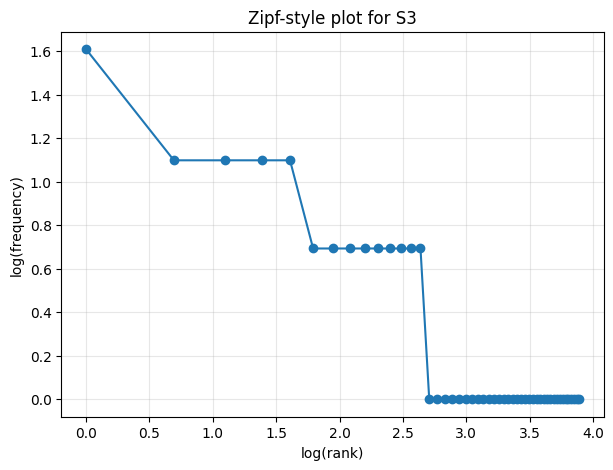

Top 5 bigrams in S1: [(('.', 'i'), 6), (('yesterday', '.'), 4), (('the', 'printer'), 2), (('was', 'working'), 2), (('working', 'yesterday'), 2)]
Top 5 bigrams in S3: [(('working', 'yesterday'), 2), (('problem', 'occurs'), 2), (('ca', "n't"), 2), (('tried', 'several'), 2), (('several', 'times'), 2)]


In [ ]:
# Q5: Corpus statistics for S1-S4
from collections import Counter
import math
import matplotlib.pyplot as plt

S1 = list(all_tokens)
S2 = [token for token in S1 if not is_punct(token)]
S3 = list(all_final)
S4 = [porter.stem(token) for token in S3]

def corpus_stats(name, tokens):
    return {
        "Corpus": name,
        "Token count": len(tokens),
        "Unique token count": len(set(tokens)),
        "TTR": len(set(tokens)) / len(tokens) if tokens else 0
    }

stats = pd.DataFrame([
    corpus_stats("S1: all tokens", S1),
    corpus_stats("S2: no punctuation", S2),
    corpus_stats("S3: final tokens", S3),
    corpus_stats("S4: S3 after Porter", S4)
])
display(stats)

print("Top 10 words in S1:", Counter(S1).most_common(10))
print("Top 10 words in S3:", Counter(S3).most_common(10))

freq = Counter(S3)
ranked = sorted(freq.values(), reverse=True)
if ranked:
    ranks = list(range(1, len(ranked) + 1))
    plt.figure(figsize=(7, 5))
    plt.plot([math.log(r) for r in ranks], [math.log(f) for f in ranked], marker="o", linestyle="-")
    plt.xlabel("log(rank)")
    plt.ylabel("log(frequency)")
    plt.title("Zipf-style plot for S3")
    plt.grid(True, alpha=0.3)
    plt.show()

def top_bigrams(tokens, n=5):
    bigrams = zip(tokens, tokens[1:])
    return Counter(bigrams).most_common(n)

print("Top 5 bigrams in S1:", top_bigrams(S1))
print("Top 5 bigrams in S3:", top_bigrams(S3))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*TTR is the number of unique tokens divided by total tokens. Removing punctuation and stopwords changes both counts; stemming can merge different word forms into the same stem, usually reducing the number of unique tokens. Therefore TTR can rise or fall depending on how much the total token count and unique-token count change.